In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


In [2]:

df = pd.read_csv("mall_customers_200.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Customers:")
display(df.head())


Dataset Shape: (200, 3)

First 5 Customers:


,CustomerID,Annual_Income_k,Spending_Score
0,CUST001,48,51
1,CUST002,29,87
2,CUST003,74,85
3,CUST004,86,18
4,CUST005,24,22


In [5]:

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   CustomerID       200 non-null    object
 1   Annual_Income_k  200 non-null    int64 
 2   Spending_Score   200 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 4.8+ KB

Statistical Summary:


,Annual_Income_k,Spending_Score
count,200.000000,200.000000
mean,60.440000,49.990000
std,25.329515,24.894146
min,15.000000,1.000000
25%,45.000000,25.000000
50%,57.000000,49.000000
75%,86.000000,73.500000
max,107.000000,98.000000



Missing Values:
CustomerID         0
Annual_Income_k    0
Spending_Score     0
dtype: int64


In [7]:

X = df[["Annual_Income_k", "Spending_Score"]]

print("Features Selected:")
display(X.head())


Features Selected:


,Annual_Income_k,Spending_Score
0,48,51
1,29,87
2,74,85
3,86,18
4,24,22


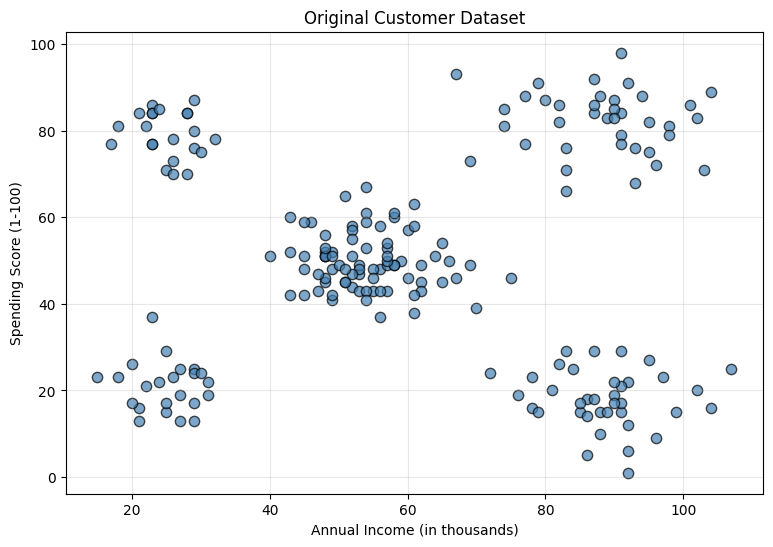

In [9]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X["Annual_Income_k"],
    X["Spending_Score"],
    color="steelblue",
    s=55,
    alpha=0.7,
    edgecolors="black"
)

plt.title("Original Customer Dataset")
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, alpha=0.3)

plt.show()


In [11]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster_3"] = kmeans.fit_predict(X)

print("Cluster Centers:")
print(kmeans.cluster_centers_)

print("\nCluster Counts:")
print(df["Cluster_3"].value_counts().sort_index())


Cluster Centers:
[[87.87179487 19.33333333]
 [88.05263158 82.18421053]
 [43.21138211 49.76422764]]

Cluster Counts:
Cluster_3
0     39
1     38
2    123
Name: count, dtype: int64


In [13]:

print("Customer Cluster Assignments:")

display(
    df[["CustomerID", "Annual_Income_k",
        "Spending_Score", "Cluster_3"]]
)


Customer Cluster Assignments:


,CustomerID,Annual_Income_k,Spending_Score,Cluster_3
0,CUST001,48,51,2
1,CUST002,29,87,2
2,CUST003,74,85,1
3,CUST004,86,18,0
4,CUST005,24,22,2
...,...,...,...,...
195,CUST196,24,85,2
196,CUST197,52,57,2
197,CUST198,87,18,0
198,CUST199,29,80,2


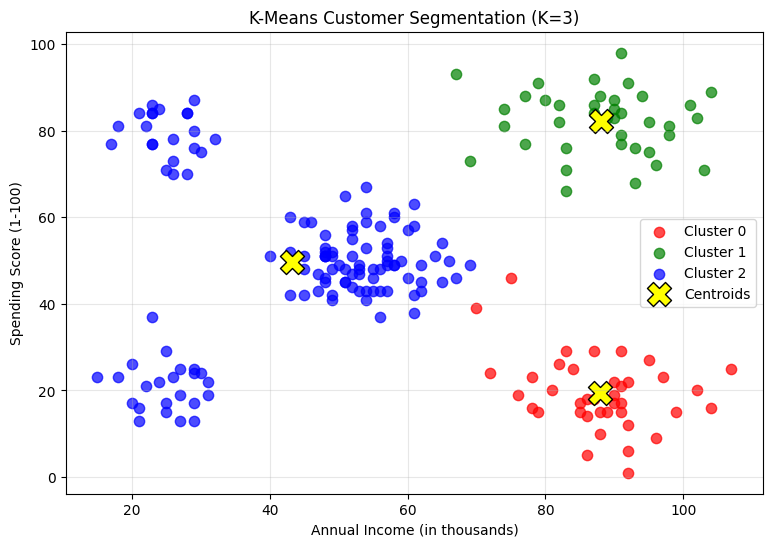

In [15]:

plt.figure(figsize=(9, 6))

colors = ["red", "green", "blue"]

for i in range(3):
    cluster_data = df[df["Cluster_3"] == i]

    plt.scatter(
        cluster_data["Annual_Income_k"],
        cluster_data["Spending_Score"],
        color=colors[i],
        label=f"Cluster {i}",
        s=55,
        alpha=0.7
    )

centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="yellow",
    marker="X",
    s=300,
    edgecolors="black",
    label="Centroids"
)

plt.title("K-Means Customer Segmentation (K=3)")
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [17]:

wcss = []

for k in range(1, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    wcss.append(model.inertia_)

wcss_table = pd.DataFrame({
    "K": range(1, 7),
    "WCSS": wcss
})

display(wcss_table.round(2))


,K,WCSS
0,1,250999.26
1,2,163520.73
2,3,80123.30
3,4,47249.82
4,5,17800.29
5,6,15323.49


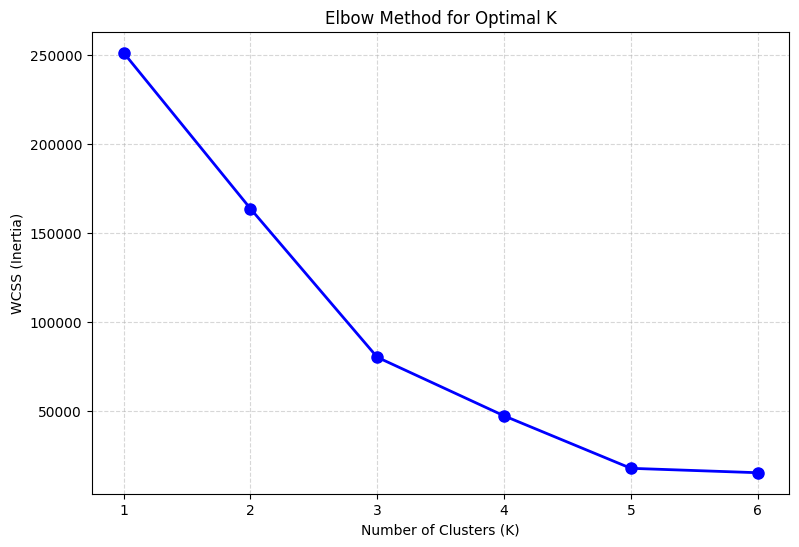

In [19]:

plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 7),
    wcss,
    marker="o",
    color="blue",
    linewidth=2,
    markersize=8
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 7))
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()


In [21]:

optimal_k = 5

final_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Final_Cluster"] = final_model.fit_predict(X)

print("Final Cluster Centers:")
print(final_model.cluster_centers_)

print("\nNumber of Customers per Cluster:")
print(df["Final_Cluster"].value_counts().sort_index())


Final Cluster Centers:
[[88.7027027  18.08108108]
 [88.05263158 82.18421053]
 [54.1625     49.7625    ]
 [25.13636364 79.18181818]
 [24.95652174 21.        ]]

Number of Customers per Cluster:
Final_Cluster
0    37
1    38
2    80
3    22
4    23
Name: count, dtype: int64


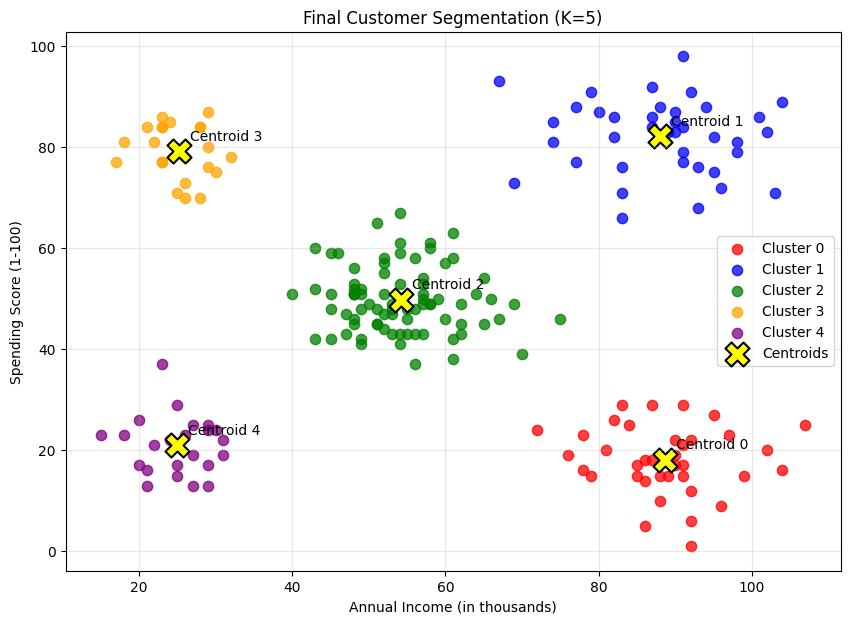

In [23]:

plt.figure(figsize=(10, 7))

colors = ["red", "blue", "green", "orange", "purple"]

for i in range(optimal_k):
    cluster_data = df[df["Final_Cluster"] == i]

    plt.scatter(
        cluster_data["Annual_Income_k"],
        cluster_data["Spending_Score"],
        color=colors[i],
        label=f"Cluster {i}",
        s=55,
        alpha=0.75
    )

centers = final_model.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="yellow",
    marker="X",
    s=300,
    edgecolors="black",
    linewidths=1.5,
    label="Centroids"
)

for i, (x, y) in enumerate(centers):
    plt.annotate(
        f"Centroid {i}",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Final Customer Segmentation (K=5)")
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [25]:

cluster_summary = df.groupby("Final_Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Income=("Annual_Income_k", "mean"),
    Average_Spending=("Spending_Score", "mean")
)

display(cluster_summary.round(2))


,Number_of_Customers,Average_Income,Average_Spending
Final_Cluster,,,
0,37,88.70,18.08
1,38,88.05,82.18
2,80,54.16,49.76
3,22,25.14,79.18
4,23,24.96,21.00


In [27]:

df.to_csv(
    "mall_customers_clustered.csv",
    index=False
)

print("Clustered dataset saved successfully!")


Clustered dataset saved successfully!


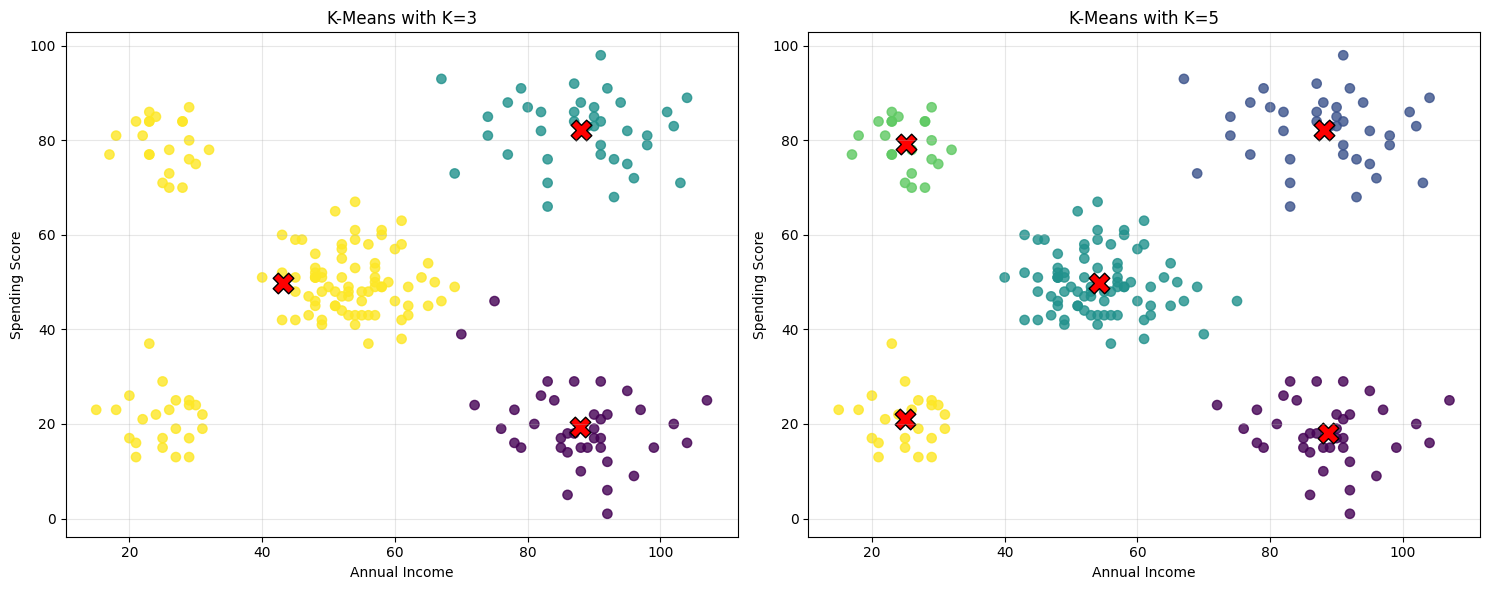

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, column, model, k in [
    (axes[0], "Cluster_3", kmeans, 3),
    (axes[1], "Final_Cluster", final_model, 5)
]:
    ax.scatter(
        X["Annual_Income_k"],
        X["Spending_Score"],
        c=df[column],
        cmap="viridis",
        s=45,
        alpha=0.8
    )

    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        c="red",
        marker="X",
        s=220,
        edgecolors="black"
    )

    ax.set_title(f"K-Means with K={k}")
    ax.set_xlabel("Annual Income")
    ax.set_ylabel("Spending Score")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
